# LeetCode #652: Find Duplicate Subtrees

https://leetcode.com/problems/find-duplicate-subtrees/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **String Serialization** | $O(n^2)$ | $O(n^2)$ |
| **Optimal: Hashing with Integer IDs ★** | $O(n)$ | $O(n)$ |

---

## Understanding the Methods

### String Serialization
Serialize each subtree into a string via post-order traversal and store serializations in a hash map. Duplicates are subtrees with the same serialization. The string concatenation at each node can take O(n) time, leading to O(n^2) total.

### Optimal: Hashing with Integer IDs ★
Assign each unique subtree structure an integer ID. The ID of a node is determined by the triple (val, left_id, right_id). Use a hash map from triples to IDs. This avoids string concatenation entirely.

**Why this is better than String Serialization:** Each node is processed in O(1) time (hash lookup of a fixed-size triple) instead of O(n) for string building, reducing total time to O(n).

**Constraints:**
* The number of nodes is in the range [1, 5000]
* -200 <= Node.val <= 200

## Solutions

### C#

In [ ]:
public class Solution {
    public IList<TreeNode> FindDuplicateSubtrees(TreeNode root) {
        // Give every distinct subtree shape a small integer id, so a subtree is
        // identified by the fixed-size triple (val, leftId, rightId) instead of
        // by an O(n) serialized string.
        var ids = new Dictionary<(int, int, int), int>();
        var count = new Dictionary<int, int>();
        var result = new List<TreeNode>();

        int Dfs(TreeNode node) {
            if (node == null) return 0;  // id 0 is reserved for the empty subtree
            int left = Dfs(node.left);
            int right = Dfs(node.right);
            var triple = (node.val, left, right);
            // Equal triples mean structurally identical subtrees
            if (!ids.TryGetValue(triple, out int sid)) {
                sid = ids.Count + 1;
                ids[triple] = sid;
            }
            int c = count.GetValueOrDefault(sid, 0) + 1;
            count[sid] = c;
            if (c == 2) result.Add(node);
            return sid;
        }

        Dfs(root);
        return result;
    }
}

### Python

In [ ]:
from collections import defaultdict

class Solution:
    def findDuplicateSubtrees(self, root) -> list:
        # Give every distinct subtree shape a small integer id, so a subtree is
        # identified by the fixed-size triple (val, leftId, rightId) instead of
        # by an O(n) serialized string.
        ids = {}
        count = defaultdict(int)
        result = []

        def dfs(node):
            if not node:
                return 0  # id 0 is reserved for the empty subtree
            left = dfs(node.left)
            right = dfs(node.right)
            triple = (node.val, left, right)
            # Equal triples mean structurally identical subtrees
            if triple not in ids:
                ids[triple] = len(ids) + 1
            sid = ids[triple]
            count[sid] += 1
            if count[sid] == 2:
                result.append(node)
            return sid

        dfs(root)
        return result

### Go

In [ ]:
func findDuplicateSubtrees(root *TreeNode) []*TreeNode {
    // Give every distinct subtree shape a small integer id, so a subtree is
    // identified by the fixed-size triple (val, leftId, rightId) instead of
    // by an O(n) serialized string.
    type triple struct{ val, left, right int }
    ids := map[triple]int{}
    count := map[int]int{}
    var result []*TreeNode

    var dfs func(*TreeNode) int
    dfs = func(node *TreeNode) int {
        if node == nil {
            return 0 // id 0 is reserved for the empty subtree
        }
        left := dfs(node.Left)
        right := dfs(node.Right)
        key := triple{node.Val, left, right}
        // Equal triples mean structurally identical subtrees
        sid, ok := ids[key]
        if !ok {
            sid = len(ids) + 1
            ids[key] = sid
        }
        count[sid]++
        if count[sid] == 2 {
            result = append(result, node)
        }
        return sid
    }

    dfs(root)
    return result
}

### Rust

In [ ]:
use std::rc::Rc;
use std::cell::RefCell;
use std::collections::HashMap;

impl Solution {
    pub fn find_duplicate_subtrees(
        root: Option<Rc<RefCell<TreeNode>>>,
    ) -> Vec<Option<Rc<RefCell<TreeNode>>>> {
        // Give every distinct subtree shape a small integer id, so a subtree is
        // identified by the fixed-size triple (val, leftId, rightId) instead of
        // by an O(n) serialized string.
        let mut ids: HashMap<(i32, i32, i32), i32> = HashMap::new();
        let mut count: HashMap<i32, i32> = HashMap::new();
        let mut result = Vec::new();

        fn dfs(
            node: &Option<Rc<RefCell<TreeNode>>>,
            ids: &mut HashMap<(i32, i32, i32), i32>,
            count: &mut HashMap<i32, i32>,
            result: &mut Vec<Option<Rc<RefCell<TreeNode>>>>,
        ) -> i32 {
            match node {
                None => 0, // id 0 is reserved for the empty subtree
                Some(n) => {
                    let borrowed = n.borrow();
                    let left = dfs(&borrowed.left, ids, count, result);
                    let right = dfs(&borrowed.right, ids, count, result);
                    let key = (borrowed.val, left, right);
                    // Equal triples mean structurally identical subtrees
                    let next_id = ids.len() as i32 + 1;
                    let sid = *ids.entry(key).or_insert(next_id);
                    let c = count.entry(sid).or_insert(0);
                    *c += 1;
                    if *c == 2 {
                        result.push(node.clone());
                    }
                    sid
                }
            }
        }

        dfs(&root, &mut ids, &mut count, &mut result);
        result
    }
}

## Example Scenarios

### 1. Common Case — Two Duplicate Subtrees
**Input:** `root = [1,2,3,4,null,2,4,null,null,4]`
Post-order serialization gives the leaf `4` the key `"4,#,#"` (seen 3 times) and the subtree `2 → 4` the key `"2,4,#,#,#"` (seen twice). Each is appended exactly once, the moment its count reaches $2$. **Output:** `[[4],[2,4]]` (any order).

### 2. Slightly Complex — Identical Leaves Under a Different Root
**Input:** `root = [2,1,1]`
Both children serialize to `"1,#,#"`, so the second one fires the duplicate rule; the root key `"2,1,#,#,1,#,#"` is unique and is never reported. **Output:** `[[1]]`

### 3. Edge Case: Time Factor — Skewed Chain, No Duplicates
**Input:** `root = [1,2,null,3,null,4,null,5]`
Every key is distinct so the map never fires, but the keys grow one node per level: string serialization copies $1+2+\dots+n$ characters, i.e. $O(n^2)$ time, while the integer-ID variant stays $O(n)$. **Output:** `[]`

### 4. Edge Case: Space Factor — Every Node Identical
**Input:** `root = [1,1,1,1,1,1,1]`
A perfect tree of all $1$s maximizes duplication: the leaf key `"1,#,#"` occurs $4$ times and the height-2 key `"1,1,#,#,1,#,#"` occurs twice, so both are reported. The map holds $O(n)$ keys of total length $O(n^2)$ — the worst space case. **Output:** `[[1],[1,1,1]]`

### 5. Almost-Impossible but Plausible — Mirrored Near-Miss
**Input:** `root = [1,2,2,3,null,null,3]`
Both `2`-nodes own a single child of value $3$, but one hangs left and one right, so `"2,3,#,#,#"` $\ne$ `"2,#,3,#,#"` — the `#` placeholders keep the structures apart. Only the leaf repeats. **Output:** `[[3]]`


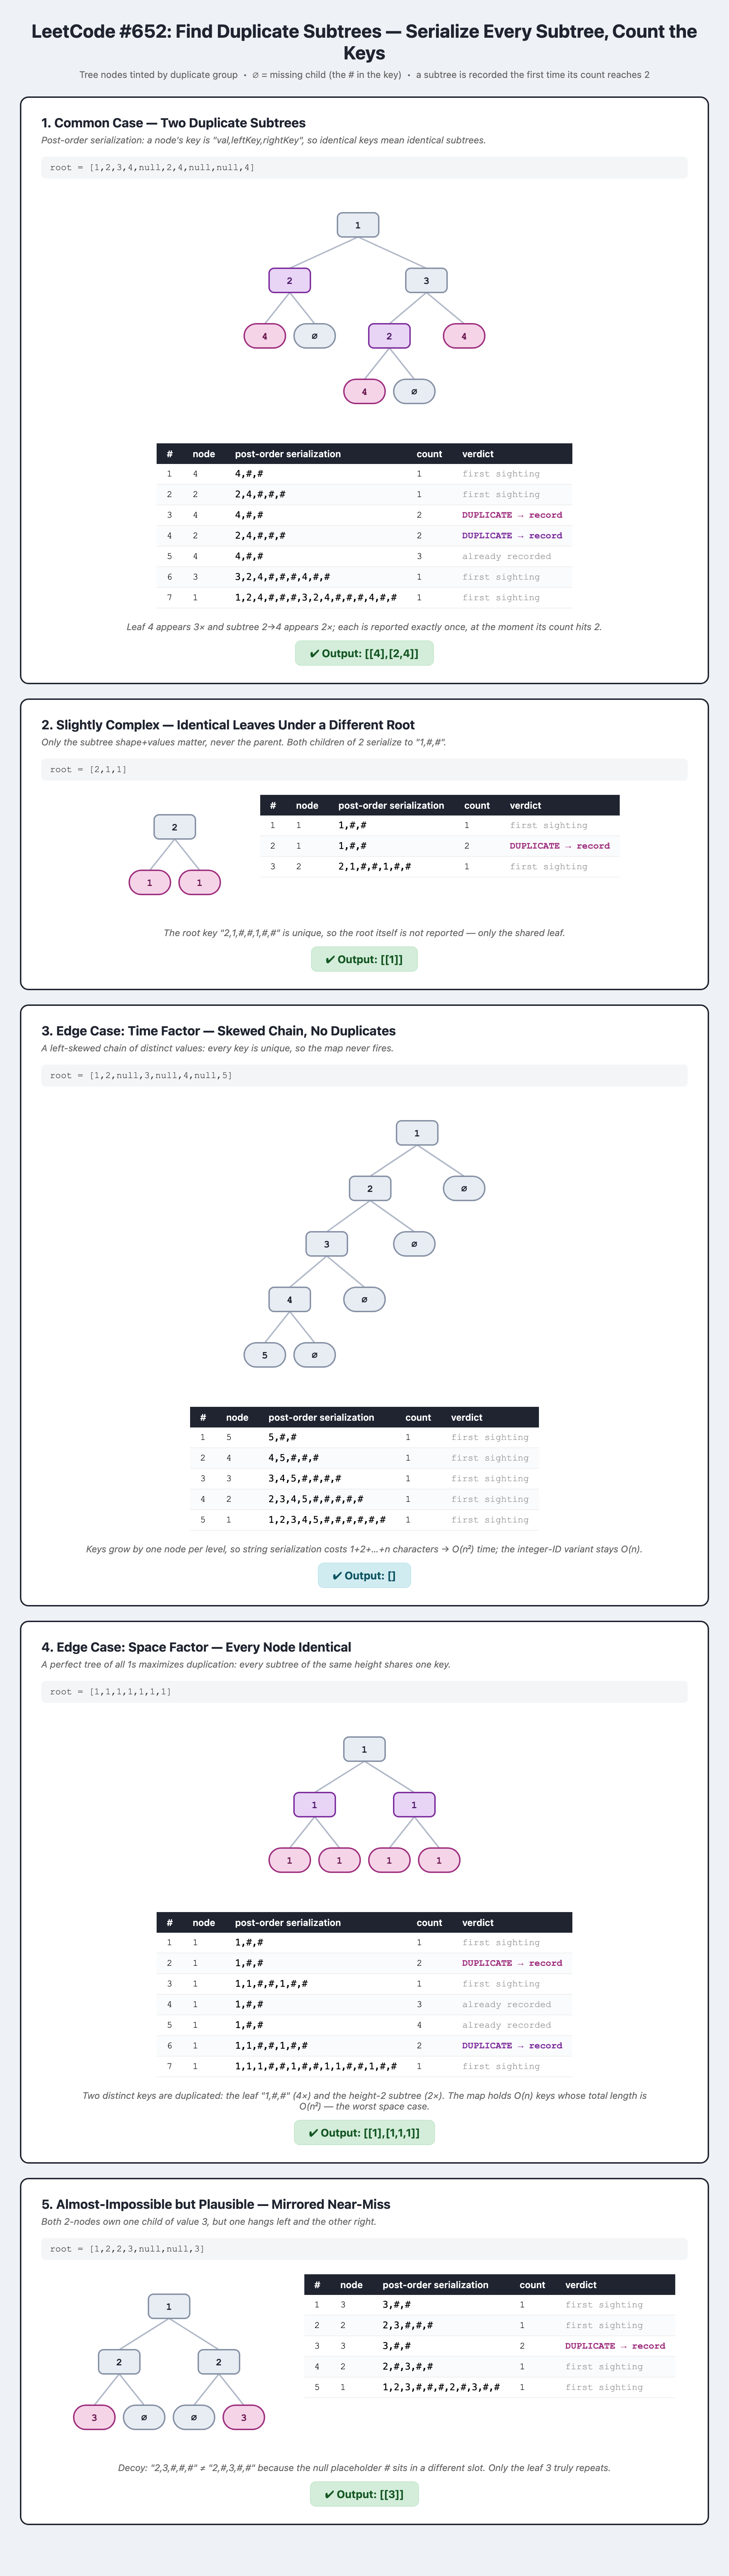